# 04. Chẩn đoán phần dư

**Mục tiêu:** kiểm tra sai số của mô hình có "hợp lý" không (Mục 6.1 của báo cáo).

**Sai số** = giá trị thực − giá trị dự báo, lấy từ chính quá trình rolling-origin ở tầm 1 tháng.
- Sai số **dương**: mô hình dự báo *thấp hơn* thực tế. Sai số **âm**: dự báo *cao hơn*.

**Hai câu hỏi:**
1. Sai số có bị **lệch một phía** không? (trung bình sai số khác 0)
2. Sai số các tháng liền nhau có **liên quan** nhau không? (tự tương quan, ACF). Nếu có, nghĩa là mô hình còn bỏ sót quy luật. Ngưỡng tham chiếu là ±1,96/√n (khoảng ±0,14 ở đây); vượt ngưỡng là đáng chú ý.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Bảng tóm tắt sai số của 4 mô hình

In [2]:
from cpi_forecast.evaluation.diagnostics import (
    rolling_origin_errors, residual_summary, autocorrelation)

df = pd.read_csv("../data/processed/cpi_monthly_clean.csv", parse_dates=["date"])
from cpi_forecast.models.naive import NaiveForecaster
from cpi_forecast.models.seasonal_naive import SeasonalNaiveForecaster
from cpi_forecast.models.moving_average import MovingAverageForecaster
from cpi_forecast.models.trend_ols import TrendOLSForecaster

models = {
    "Naive": NaiveForecaster,
    "Seasonal Naive": SeasonalNaiveForecaster,
    "Trung bình trượt (k=3)": lambda: MovingAverageForecaster(k=3),
    "Hồi quy xu hướng (OLS)": TrendOLSForecaster,
}


def summary_table(col):
    rows = []
    for name, factory in models.items():
        s = residual_summary(rolling_origin_errors(df[col].to_numpy(), factory, h=1))
        rows.append({"Mô hình": name,
                     "Trung bình sai số": round(s["trung_binh"], 3),
                     "Độ lệch chuẩn": round(s["do_lech_chuan"], 3),
                     "ACF lag 1": round(s["acf_lag1"], 2),
                     "ACF lag 12": round(s["acf_lag12"], 2)})
    return pd.DataFrame(rows)


print("CHUỖI CHỈ SỐ"); print(summary_table("index").to_string(index=False))
print("CHUỖI % THAY ĐỔI"); print(summary_table("pct").to_string(index=False))

CHUỖI CHỈ SỐ
               Mô hình  Trung bình sai số  Độ lệch chuẩn  ACF lag 1  ACF lag 12
                 Naive              0.857          1.269       0.46        0.09
        Seasonal Naive             10.465          6.973       0.97        0.24
Trung bình trượt (k=3)              1.729          2.001       0.75        0.08
Hồi quy xu hướng (OLS)            -11.724          9.511       0.98        0.68
CHUỖI % THAY ĐỔI
               Mô hình  Trung bình sai số  Độ lệch chuẩn  ACF lag 1  ACF lag 12
                 Naive             -0.009          0.515      -0.13        0.14
        Seasonal Naive             -0.033          0.734       0.56       -0.43
Trung bình trượt (k=3)             -0.015          0.548       0.31        0.13
Hồi quy xu hướng (OLS)              0.058          0.556       0.55        0.18


**Cách đọc bảng:**
- **Chuỗi chỉ số:** Seasonal Naive (+10,5) và trung bình trượt (+1,7) dự báo thấp; OLS dự báo cao (−11,7). Cả ba có ACF lag 1 rất cao (0,97; 0,75; 0,98): sai số thay đổi chậm, tức các mô hình này bỏ sót xu hướng. Naive lệch ít nhất (+0,86).
- **Chuỗi % thay đổi:** trung bình sai số của cả 4 mô hình gần 0, tức không lệch một phía. Naive có ACF lag 1 = −0,13, nằm trong ngưỡng: đây là mô hình có sai số "sạch" nhất ở tầm 1.
- ACF lag 12 = −0,43 của Seasonal Naive có một phần do cách tính (sai số = y_t − y_(t−12), nên hai sai số cách nhau 12 tháng dùng chung một giá trị với dấu ngược nhau), đừng hiểu nó là mùa vụ còn sót lại.
- Chẩn đoán chỉ làm ở tầm 1 tháng, vì ở tầm xa các sai số liên tiếp trùng nhau một phần nên tự tương quan xuất hiện sẵn.

## 2. Ba biểu đồ cho Naive trên chuỗi chỉ số

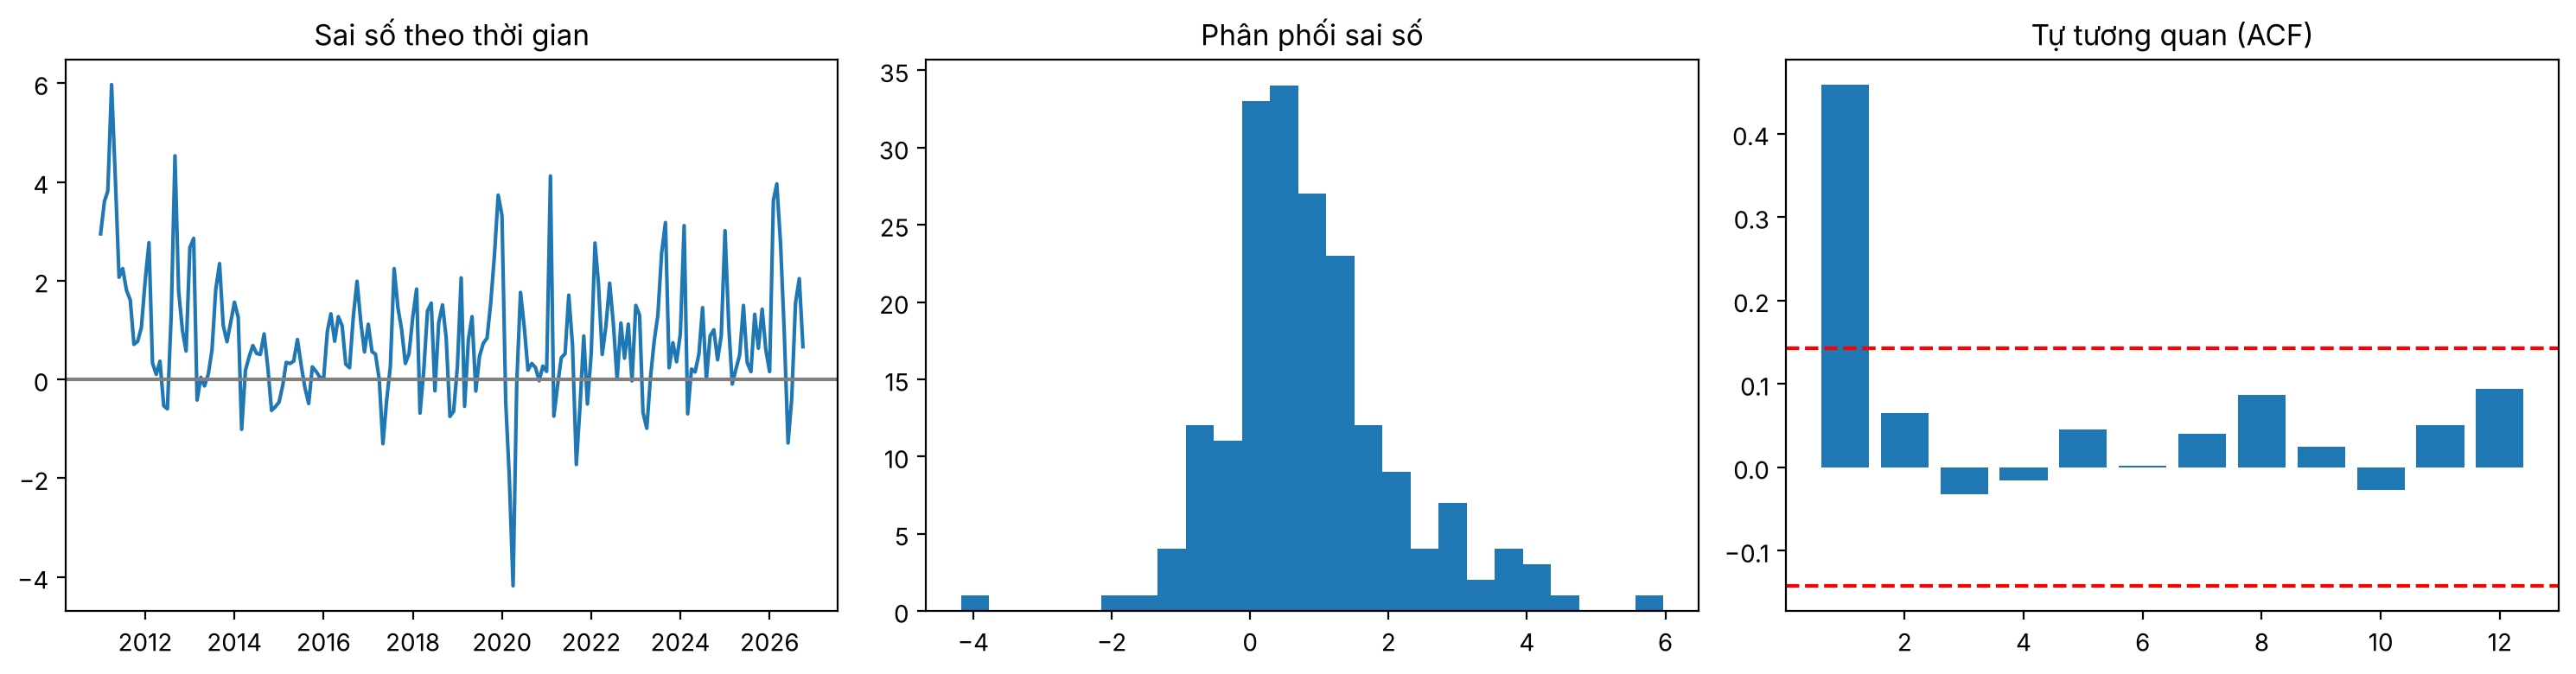

In [3]:
e = rolling_origin_errors(df["index"].to_numpy(), NaiveForecaster, h=1)
dates = df["date"].iloc[60:]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(dates, e); axes[0].axhline(0, color="gray"); axes[0].set_title("Sai số theo thời gian")
axes[1].hist(e, bins=25); axes[1].set_title("Phân phối sai số")
band = 1.96 / np.sqrt(len(e))
axes[2].bar(range(1, 13), autocorrelation(e, 12))
axes[2].axhline(band, ls="--", color="red"); axes[2].axhline(-band, ls="--", color="red")
axes[2].set_title("Tự tương quan (ACF)")
plt.tight_layout(); plt.show()

**Cách đọc:**
- **Sai số theo thời gian:** phần lớn nằm trên 0 (Naive thường dự báo thấp hơn thực tế vì chỉ số tăng đều); có vài đỉnh cao và một đáy sâu gần −4 vào khoảng năm 2020.
- **Phân phối:** lệch về phía dương, đỉnh quanh +0,5 đến +1, đuôi dài sang phải.
- **ACF:** chỉ độ trễ 1 (0,46) vượt đường đỏ; các độ trễ khác, kể cả độ trễ 12, nằm trong ngưỡng, nên chưa thấy dấu hiệu mùa vụ rõ.

Nói bằng lời: Naive luôn thấp hơn thực tế khoảng 0,86 điểm mỗi tháng, và tháng tăng mạnh thường được theo sau bởi một tháng tăng mạnh nữa, điều mà Naive không nắm được.